# Multi-Input ResNet1D — ECG Multi-Label Classification

**Task:** Multi-label classification of 12-lead ECG signals into 5 diagnostic superclasses:  
NORM, MI, STTC, CD, HYP

**Architecture:** Multi-Input 1D ResNet + Feature MLP (dual branch)  
**Data:** Preprocessed arrays from `preprocessing.ipynb` saved to Google Drive  
**Runtime:** GPU recommended

## 1. Setup & Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [31]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, callbacks
from sklearn.metrics import classification_report, roc_auc_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

# Set seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Preprocessed Data from Drive

In [32]:
drive_path = 'drive/MyDrive/ECG'
data_dir = os.path.join(drive_path, "preprocessed")

# Load metadata
with open(os.path.join(data_dir, "metadata.json"), "r") as f:
    meta = json.load(f)

SUPERCLASSES = meta["superclasses"]
SIGNAL_SHAPE = tuple(meta["signal_shape"])
N_FEATURES = meta["n_features"]
LEAD_NAMES = meta["lead_names"]

# Load arrays
X_train = np.load(os.path.join(data_dir, "X_train.npy"))
X_val   = np.load(os.path.join(data_dir, "X_val.npy"))
X_test  = np.load(os.path.join(data_dir, "X_test.npy"))
Y_train = np.load(os.path.join(data_dir, "Y_train.npy"))
Y_val   = np.load(os.path.join(data_dir, "Y_val.npy"))
Y_test  = np.load(os.path.join(data_dir, "Y_test.npy"))
F_train = np.load(os.path.join(data_dir, "F_train.npy"))
F_val   = np.load(os.path.join(data_dir, "F_val.npy"))
F_test  = np.load(os.path.join(data_dir, "F_test.npy"))

print(f"Signal shape: {SIGNAL_SHAPE}, Features: {N_FEATURES}")
print(f"Train: {X_train.shape[0]:>6} | Val: {X_val.shape[0]:>5} | Test: {X_test.shape[0]:>5}")
print(f"Superclasses: {SUPERCLASSES}")
print(f"\nLabel distribution (train):")
for i, sc in enumerate(SUPERCLASSES):
    print(f"  {sc}: {int(Y_train[:, i].sum())}")

Signal shape: (1000, 12), Features: 531
Train:  17418 | Val:  2183 | Test:  2198
Superclasses: ['NORM', 'MI', 'STTC', 'CD', 'HYP']

Label distribution (train):
  NORM: 7596
  MI: 4379
  STTC: 4087
  CD: 3907
  HYP: 2119


## 2.1 Class Imbalance — Per-Class Loss Weights

Compute inverse-frequency weights for each of the 5 superclasses to mitigate class imbalance in the multi-label BCE loss.

In [33]:
# ── Per-class weights (inverse frequency) ──
# For multi-label: weight_j = N / (C * count_j)  where N=total samples, C=num_classes
n_samples = Y_train.shape[0]
n_classes = Y_train.shape[1]

pos_counts = Y_train.sum(axis=0)  # positive samples per class
neg_counts = n_samples - pos_counts

# Compute pos_weight for each class: ratio of negatives to positives
# Used inside a weighted BCE to up-weight minority positives
class_weights = neg_counts / (pos_counts + 1e-7)

print("Class imbalance analysis (training set):")
print(f"{'Class':<8} {'Pos':>6} {'Neg':>6} {'Pos%':>7} {'Weight':>8}")
print("-" * 42)
for i, sc in enumerate(SUPERCLASSES):
    pct = pos_counts[i] / n_samples * 100
    print(f"{sc:<8} {int(pos_counts[i]):>6} {int(neg_counts[i]):>6} {pct:>6.1f}% {class_weights[i]:>8.2f}")

# Convert to tensor for use in custom loss
class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)
print(f"\nClass weight tensor: {class_weights_tensor.numpy()}")

Class imbalance analysis (training set):
Class       Pos    Neg    Pos%   Weight
------------------------------------------
NORM       7596   9822   43.6%     1.29
MI         4379  13039   25.1%     2.98
STTC       4087  13331   23.5%     3.26
CD         3907  13511   22.4%     3.46
HYP        2119  15299   12.2%     7.22

Class weight tensor: [1.293049  2.9776204 3.2618058 3.458152  7.219915 ]


## 2.2 Data Augmentation & Frequency-Domain Artifact Suppression

**Augmentation (per-batch, on GPU):**
- **Random time masking:** zero out contiguous time segments (mask ratio 0.2, apply prob 0.8)
- **Random lead masking:** zero out entire leads to simulate electrode dropout
- **Gaussian noise injection:** small additive noise for regularization

**Frequency-domain artifact suppression:**
- Bandpass filter (0.5–40 Hz) applied via FFT to remove baseline wander & high-freq noise
- Applied once to all data before training

In [34]:
# ── Frequency-Domain Artifact Suppression ──
# Bandpass filter via FFT: keep 0.5–40 Hz, suppress baseline wander & high-freq noise
# Applied once to all splits (deterministic preprocessing)

def fft_bandpass_filter(X, fs=100, low=0.5, high=40.0):
    """
    Apply FFT-based bandpass filter to ECG signals.
    X: (N, timesteps, leads) numpy array
    Returns filtered X of same shape.
    """
    N_samples, T, L = X.shape
    freqs = np.fft.rfftfreq(T, d=1.0/fs)  # frequency bins
    
    # Create bandpass mask
    mask = np.ones(len(freqs), dtype=np.float32)
    mask[freqs < low]  = 0.0  # suppress below 0.5 Hz (baseline wander)
    mask[freqs > high] = 0.0  # suppress above 40 Hz (high-freq noise/powerline)
    
    # Smooth transition (Tukey-style) to avoid ringing
    transition_width = 0.5  # Hz
    for i, f in enumerate(freqs):
        if low <= f < low + transition_width:
            mask[i] = (f - low) / transition_width
        elif high - transition_width < f <= high:
            mask[i] = (high - f) / transition_width
    
    # Apply per-lead
    X_filtered = np.zeros_like(X)
    for lead in range(L):
        fft_data = np.fft.rfft(X[:, :, lead], axis=1)
        fft_data *= mask[np.newaxis, :]
        X_filtered[:, :, lead] = np.fft.irfft(fft_data, n=T, axis=1)
    
    return X_filtered.astype(np.float32)

print("Applying FFT bandpass filter (0.5–40 Hz)...")
X_train = fft_bandpass_filter(X_train)
X_val   = fft_bandpass_filter(X_val)
X_test  = fft_bandpass_filter(X_test)
print(f"✓ Artifact suppression complete. X_train: {X_train.shape}")

Applying FFT bandpass filter (0.5–40 Hz)...
✓ Artifact suppression complete. X_train: (17418, 1000, 12)


In [35]:
# ── Data Augmentation Layer (applied on-the-fly during training) ──
# Random masking of contiguous time–frequency segments
# Mask ratio: 0.2, application probability: 0.8 per batch (Kang et al., 2025)

class ECGAugmentation(layers.Layer):
    """
    On-the-fly ECG augmentation applied only during training:
    1. Time masking: zero out contiguous time segments (mask_ratio=0.2, prob=0.8)
    2. Lead masking: zero out entire leads to simulate electrode dropout (prob=0.3)
    3. Gaussian noise: additive noise for regularization (std=0.05)
    """
    def __init__(self, mask_ratio=0.2, mask_prob=0.8, lead_mask_prob=0.3, 
                 noise_std=0.05, **kwargs):
        super().__init__(**kwargs)
        self.mask_ratio = mask_ratio
        self.mask_prob = mask_prob
        self.lead_mask_prob = lead_mask_prob
        self.noise_std = noise_std
    
    def call(self, inputs, training=None):
        if not training:
            return inputs
        
        x = inputs
        batch_size = tf.shape(x)[0]
        timesteps = tf.shape(x)[1]
        n_leads = tf.shape(x)[2]
        
        # 1. Time masking — zero out contiguous segment (mask_ratio=0.2, prob=0.8)
        apply_mask = tf.random.uniform([batch_size, 1, 1]) < self.mask_prob
        mask_len = tf.cast(tf.cast(timesteps, tf.float32) * self.mask_ratio, tf.int32)
        max_start = timesteps - mask_len
        starts = tf.random.uniform([batch_size], 0, tf.cast(max_start, tf.float32))
        starts = tf.cast(starts, tf.int32)
        
        # Build time mask per sample
        time_range = tf.range(timesteps)[tf.newaxis, :, tf.newaxis]  # (1, T, 1)
        starts_exp = starts[:, tf.newaxis, tf.newaxis]  # (B, 1, 1)
        ends_exp = starts_exp + mask_len
        time_mask = tf.cast(
            (time_range >= starts_exp) & (time_range < ends_exp), tf.float32
        )  # (B, T, 1) — 1 where masked
        time_mask = time_mask * tf.cast(apply_mask, tf.float32)
        x = x * (1.0 - time_mask)
        
        # 2. Lead masking — zero out random leads (simulate electrode dropout)
        lead_mask = tf.cast(
            tf.random.uniform([batch_size, 1, n_leads]) < self.lead_mask_prob, tf.float32
        )
        # Don't mask ALL leads — keep at least 6
        lead_mask = lead_mask * tf.cast(
            tf.reduce_sum(lead_mask, axis=-1, keepdims=True) < tf.cast(n_leads // 2, tf.float32),
            tf.float32
        )
        x = x * (1.0 - lead_mask)
        
        # 3. Gaussian noise
        noise = tf.random.normal(tf.shape(x), stddev=self.noise_std)
        x = x + noise
        
        return x
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "mask_ratio": self.mask_ratio,
            "mask_prob": self.mask_prob,
            "lead_mask_prob": self.lead_mask_prob,
            "noise_std": self.noise_std,
        })
        return config

print("✓ ECGAugmentation layer defined")
print(f"  Time mask ratio: 0.2, apply prob: 0.8")
print(f"  Lead mask prob: 0.3 (max n_leads//2)")
print(f"  Gaussian noise std: 0.05")

✓ ECGAugmentation layer defined
  Time mask ratio: 0.2, apply prob: 0.8
  Lead mask prob: 0.3 (max n_leads//2)
  Gaussian noise std: 0.05


## 3. Model Architecture — Multi-Input ResNet1D

**Branch 1 (Signal):** 1D ResNet with residual blocks over the 12-lead ECG signal `(1000, 12)`  
**Branch 2 (Features):** Small MLP over PTB-XL+ ECGDeli features  
**Fusion:** Concatenate both branches → Dense → 5-output sigmoid (multi-label)

In [17]:
def residual_block(x, filters, kernel_size=15, strides=1, dilation=1):
    """1D Residual block with batch norm and skip connection."""
    shortcut = x
    
    # Main path
    out = layers.Conv1D(filters, kernel_size, strides=strides, padding="same",
                        dilation_rate=dilation, kernel_initializer="he_normal")(x)
    out = layers.BatchNormalization()(out)
    out = layers.ReLU()(out)
    out = layers.Dropout(0.1)(out)
    
    out = layers.Conv1D(filters, kernel_size, padding="same",
                        dilation_rate=dilation, kernel_initializer="he_normal")(out)
    out = layers.BatchNormalization()(out)
    
    # Skip connection — adjust dimensions if needed
    if shortcut.shape[-1] != filters or strides > 1:
        shortcut = layers.Conv1D(filters, 1, strides=strides, padding="same")(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    
    out = layers.Add()([shortcut, out])
    out = layers.ReLU()(out)
    return out


def build_model(signal_shape=(1000, 12), n_features=None, n_classes=5,
                use_augmentation=True):
    """
    Multi-input ResNet1D for ECG multi-label classification.
    
    Branch 1: 1D ResNet over raw signal (with on-the-fly augmentation)
    Branch 2: MLP over structured features (PTB-XL+)
    """
    # ── Branch 1: Signal (1D ResNet) ──
    signal_input = layers.Input(shape=signal_shape, name="signal_input")
    
    # Apply data augmentation (only active during training)
    if use_augmentation:
        x = ECGAugmentation(
            mask_ratio=0.2, mask_prob=0.8,
            lead_mask_prob=0.3, noise_std=0.05
        )(signal_input)
    else:
        x = signal_input
    
    x = layers.Conv1D(64, 15, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)  # (500, 64)
    
    # Residual blocks with increasing filters
    x = residual_block(x, 64,  kernel_size=15)
    x = residual_block(x, 64,  kernel_size=15)
    x = layers.MaxPooling1D(2)(x)  # (250, 64)
    
    x = residual_block(x, 128, kernel_size=11)
    x = residual_block(x, 128, kernel_size=11)
    x = layers.MaxPooling1D(2)(x)  # (125, 128)
    
    x = residual_block(x, 256, kernel_size=7)
    x = residual_block(x, 256, kernel_size=7)
    x = layers.MaxPooling1D(2)(x)  # (62, 256)
    
    x = residual_block(x, 512, kernel_size=5)
    
    x = layers.GlobalAveragePooling1D()(x)  # (512,)
    x = layers.Dropout(0.3)(x)
    
    signal_branch = x
    
    # ── Branch 2: Features MLP ──
    if n_features is not None and n_features > 0:
        feature_input = layers.Input(shape=(n_features,), name="feature_input")
        f = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(feature_input)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.3)(f)
        f = layers.Dense(64, activation="relu", kernel_initializer="he_normal")(f)
        f = layers.BatchNormalization()(f)
        f = layers.Dropout(0.2)(f)
        
        # Fusion
        merged = layers.Concatenate()([signal_branch, f])
        inputs = [signal_input, feature_input]
    else:
        merged = signal_branch
        inputs = [signal_input]
    
    # ── Classification Head ──
    merged = layers.Dense(256, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.BatchNormalization()(merged)
    merged = layers.Dropout(0.4)(merged)
    merged = layers.Dense(128, activation="relu", kernel_initializer="he_normal")(merged)
    merged = layers.Dropout(0.3)(merged)
    
    output = layers.Dense(n_classes, activation="sigmoid", name="output")(merged)
    
    model = Model(inputs=inputs, outputs=output)
    return model


# Build the model (augmentation is embedded as a layer — active only during training)
model = build_model(
    signal_shape=SIGNAL_SHAPE, n_features=N_FEATURES, n_classes=5,
    use_augmentation=True
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ signal_input        │ (None, 1000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ecg_augmentation    │ (None, 1000, 12)  │          0 │ signal_input[0][… │
│ (ECGAugmentation)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 1000, 64)  │     11,584 │ ecg_augmentation… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1000, 64)  │        256 │ conv1d_18[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_15 (ReLU)     │ (None, 1000, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 500, 64)   │          0 │ re_lu_15[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 500, 64)   │     61,504 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 64)   │        256 │ conv1d_19[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_16 (ReLU)     │ (None, 500, 64)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 500, 64)   │          0 │ re_lu_16[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 500, 64)   │     61,504 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 64)   │        256 │ conv1d_20[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 500, 64)   │          0 │ max_pooling1d_4[… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_17 (ReLU)     │ (None, 500, 64)   │          0 │ add_7[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 500, 64)   │     61,504 │ re_lu_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 64)   │        256 │ conv1d_21[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 500, 64)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 500, 64)   │          0 │ re_lu_18[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 500, 64)   │     61,504 │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 500, 64)   │        256 │ conv1d_22[0][0] 

 Total params: 4,910,085 (18.73 MB)

 Trainable params: 4,901,637 (18.70 MB)

 Non-trainable params: 8,448 (33.00 KB)

## 4. Compile & Train

In [18]:
# Save paths on Drive
model_save_dir = os.path.join(drive_path, "models")
os.makedirs(model_save_dir, exist_ok=True)
best_model_path = os.path.join(model_save_dir, "best_ecg_model.keras")

# ── Weighted Binary Cross-Entropy (per-class) ──
# Uses class_weights_tensor computed in Section 2.1
def weighted_bce(y_true, y_pred):
    """
    Per-class weighted binary cross-entropy.
    Positive samples are up-weighted by class_weights_tensor (neg/pos ratio).
    """
    bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)  # (batch, 5)
    weights = y_true * class_weights_tensor + (1.0 - y_true) * 1.0
    return tf.reduce_mean(bce * weights, axis=-1)

# Compile model with weighted loss
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=weighted_bce,
    metrics=[
        keras.metrics.AUC(name="auc", multi_label=True),
        keras.metrics.F1Score(name="f1", average="macro", threshold=0.5),
    ]
)

# Callbacks
cb = [
    callbacks.EarlyStopping(
        monitor="val_auc", patience=10, mode="max", 
        restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_auc", factor=0.5, patience=5, 
        mode="max", min_lr=1e-6, verbose=1
    ),
    callbacks.ModelCheckpoint(
        best_model_path, monitor="val_auc", 
        mode="max", save_best_only=True, verbose=1
    ),
]

print("Model compiled ✓  (weighted BCE loss)")
print(f"Class weights: {dict(zip(SUPERCLASSES, class_weights_tensor.numpy().tolist()))}")
print(f"Trainable parameters: {model.count_params():,}")
print(f"Checkpoints will be saved to: {best_model_path}")

Model compiled ✓  (weighted BCE loss)
Class weights: {'NORM': 1.2930489778518677, 'MI': 2.9776203632354736, 'STTC': 3.261805772781372, 'CD': 3.4581520557403564, 'HYP': 7.21991491317749}
Trainable parameters: 4,910,085
Checkpoints will be saved to: drive/MyDrive/ECG/models/best_ecg_model.keras


In [19]:
# Train the model
BATCH_SIZE = 64
EPOCHS = 50

history = model.fit(
    [X_train, F_train], Y_train,
    validation_data=([X_val, F_val], Y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=cb,
    verbose=1,
)

print("\n✓ Training complete")

Epoch 1/50
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - auc: 0.7321 - f1: 0.4964 - loss: 1.0139
Epoch 1: val_auc improved from -inf to 0.85040, saving model to drive/MyDrive/ECG/models/best_ecg_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 80s 172ms/step - auc: 0.7323 - f1: 0.4966 - loss: 1.0134 - val_auc: 0.8504 - val_f1: 0.5385 - val_loss: 1.0871 - learning_rate: 0.0010
Epoch 2/50
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - auc: 0.8521 - f1: 0.6120 - loss: 0.7240
Epoch 2: val_auc improved from 0.85040 to 0.85275, saving model to drive/MyDrive/ECG/models/best_ecg_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 24s 86ms/step - auc: 0.8521 - f1: 0.6121 - loss: 0.7239 - val_auc: 0.8528 - val_f1: 0.6073 - val_loss: 0.7902 - learning_rate: 0.0010
Epoch 3/50
272/273 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - auc: 0.8780 - f1: 0.6399 - loss: 0.6549
Epoch 3: val_auc improved from 0.85275 to 0.89167, saving model to drive/MyDrive/ECG/models/best_ecg_model.keras
273/273 ━━━━━━━━━━━━━━━━━━━━ 24s 87ms/step - auc: 0

## 5. Training Curves

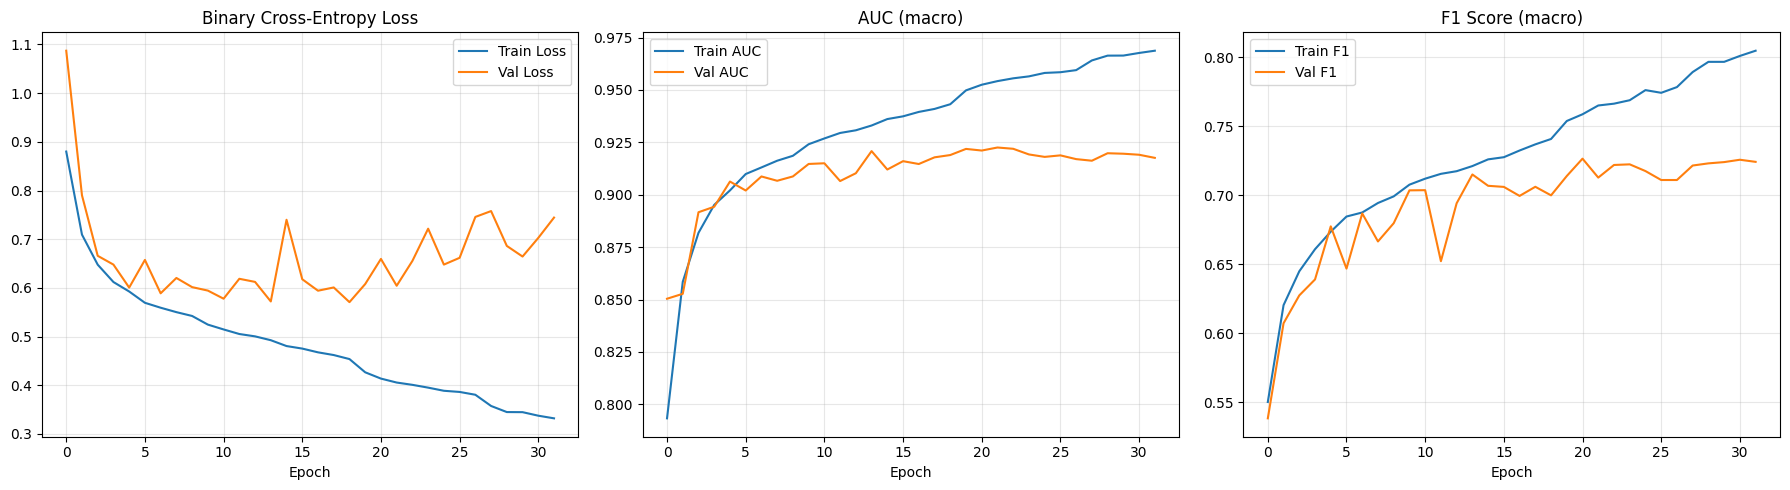

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Binary Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# AUC
axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("AUC (macro)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# F1
axes[2].plot(history.history["f1"], label="Train F1")
axes[2].plot(history.history["val_f1"], label="Val F1")
axes[2].set_title("F1 Score (macro)")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Evaluate on Test Set (Fold 10)

In [36]:
# Load best model (must pass custom objects for ECGAugmentation & weighted_bce)
best_model = keras.models.load_model(best_model_path, custom_objects={
    "weighted_bce": weighted_bce,
    "ECGAugmentation": ECGAugmentation,
})

# Predict probabilities
Y_pred_prob = best_model.predict([X_test, F_test], batch_size=64, verbose=1)
Y_pred = (Y_pred_prob >= 0.5).astype(int)

# ── Per-class AUC ──
print("=" * 60)
print("PER-CLASS METRICS (Test Set — Fold 10)")
print("=" * 60)

auc_scores = {}
for i, sc in enumerate(SUPERCLASSES):
    try:
        auc = roc_auc_score(Y_test[:, i], Y_pred_prob[:, i])
    except ValueError:
        auc = float("nan")
    auc_scores[sc] = auc
    print(f"  {sc:>5}: AUC = {auc:.4f}")

macro_auc = np.nanmean(list(auc_scores.values()))
print(f"\n  Macro AUC: {macro_auc:.4f}")

# ── Classification Report ──
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(Y_test, Y_pred, target_names=SUPERCLASSES, zero_division=0))

# ── Per-class F1 ──
f1_per_class = f1_score(Y_test, Y_pred, average=None, zero_division=0)
f1_macro = f1_score(Y_test, Y_pred, average="macro", zero_division=0)
print(f"Per-class F1: {dict(zip(SUPERCLASSES, [f'{f:.4f}' for f in f1_per_class]))}")
print(f"Macro F1:     {f1_macro:.4f}")

35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step
PER-CLASS METRICS (Test Set — Fold 10)
   NORM: AUC = 0.9437
     MI: AUC = 0.9145
   STTC: AUC = 0.9258
     CD: AUC = 0.9102
    HYP: AUC = 0.8997

  Macro AUC: 0.9188

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        NORM       0.75      0.95      0.84       963
          MI       0.70      0.77      0.73       550
        STTC       0.70      0.79      0.74       506
          CD       0.64      0.79      0.71       496
         HYP       0.37      0.82      0.51       262

   micro avg       0.65      0.84      0.74      2777
   macro avg       0.63      0.82      0.71      2777
weighted avg       0.68      0.84      0.75      2777
 samples avg       0.71      0.83      0.74      2777

Per-class F1: {'NORM': '0.8408', 'MI': '0.7321', 'STTC': '0.7432', 'CD': '0.7112', 'HYP': '0.5065'}
Macro F1:     0.7068


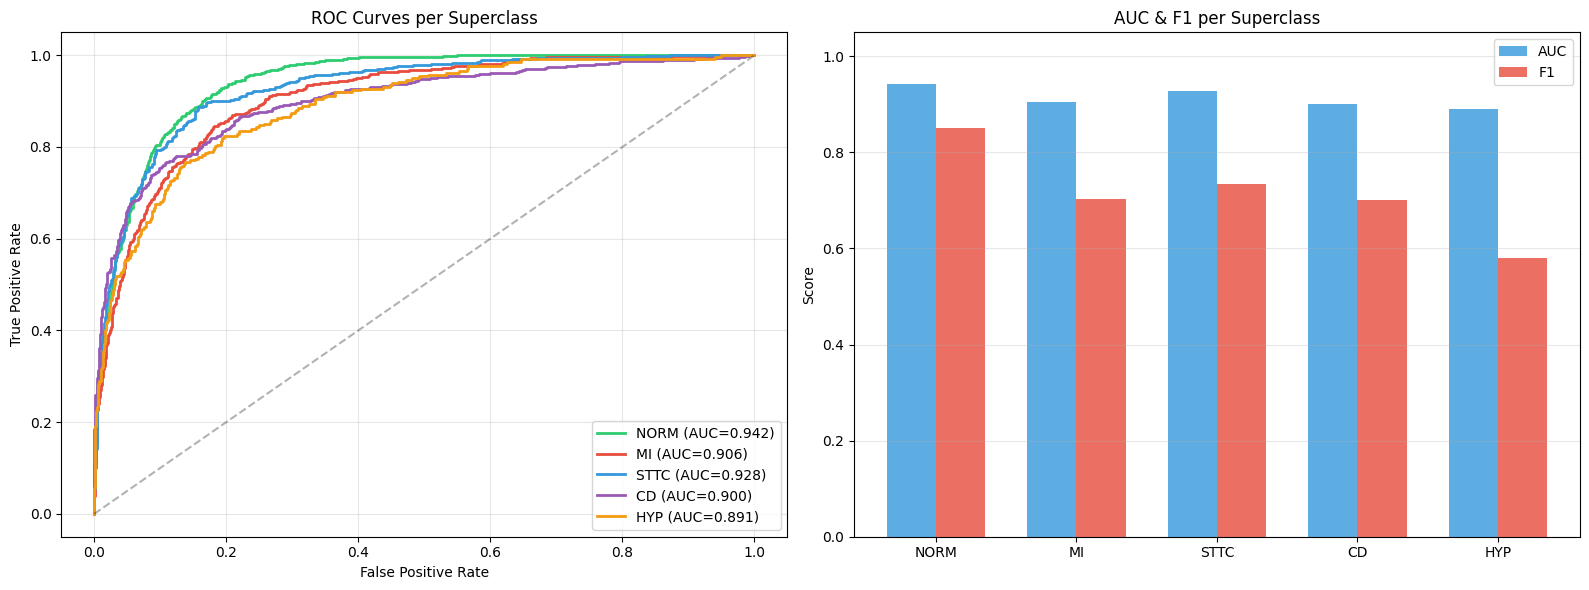

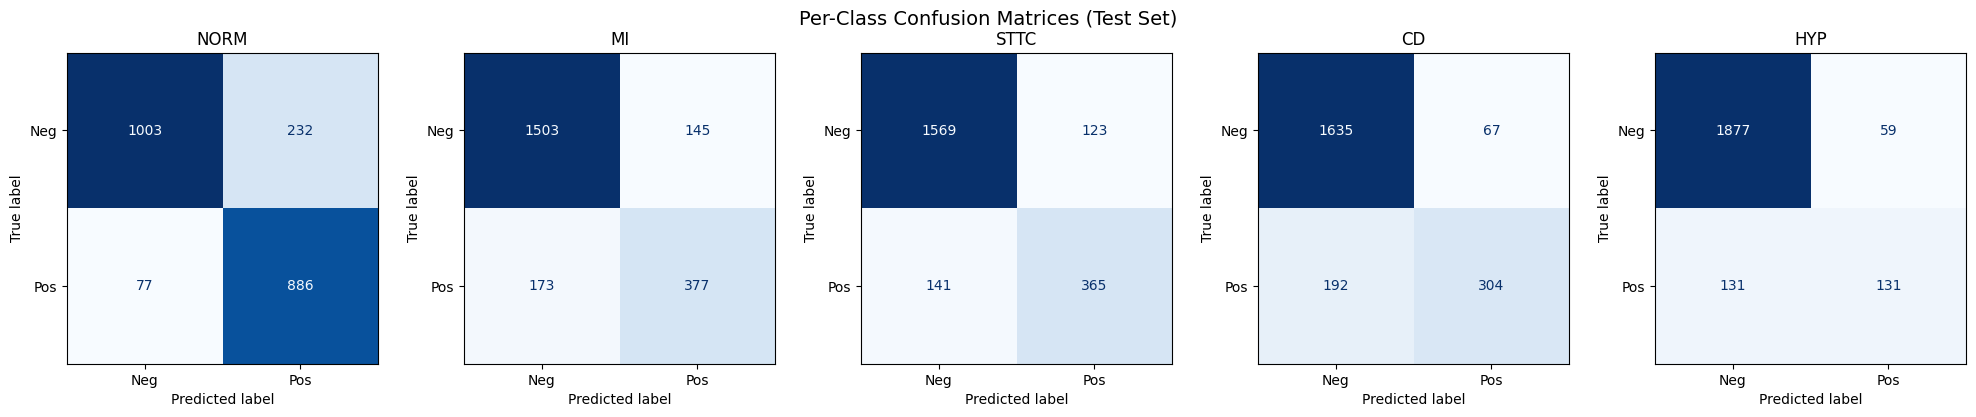

In [23]:
# ── ROC Curves per class ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ["#2ecc71", "#e74c3c", "#3498db", "#9b59b6", "#f39c12"]
for i, (sc, color) in enumerate(zip(SUPERCLASSES, colors)):
    fpr, tpr, _ = roc_curve(Y_test[:, i], Y_pred_prob[:, i])
    axes[0].plot(fpr, tpr, label=f"{sc} (AUC={auc_scores[sc]:.3f})", color=color, linewidth=2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves per Superclass")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# ── Per-class bar chart (AUC & F1) ──
x_pos = np.arange(len(SUPERCLASSES))
width = 0.35
axes[1].bar(x_pos - width/2, [auc_scores[sc] for sc in SUPERCLASSES], width, 
            label="AUC", color="#3498db", alpha=0.8)
axes[1].bar(x_pos + width/2, f1_per_class, width, 
            label="F1", color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(SUPERCLASSES)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Score")
axes[1].set_title("AUC & F1 per Superclass")
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

# ── Confusion matrices (one per class) ──
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, (ax, sc) in enumerate(zip(axes, SUPERCLASSES)):
    cm = confusion_matrix(Y_test[:, i], Y_pred[:, i])
    ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(sc)
plt.suptitle("Per-Class Confusion Matrices (Test Set)", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(model_save_dir, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Edge Optimization — TFLite Conversion 

Convert the best model to TensorFlow Lite with:
1. **Float16 quantization** — reduces size ~50% with minimal accuracy loss  
2. **Dynamic range quantization** — further compression for edge deployment

In [24]:
# ── TFLite Conversion ──

# 1. Float16 quantization
converter_fp16 = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter_fp16.optimizations = [tf.lite.Optimize.DEFAULT]
converter_fp16.target_spec.supported_types = [tf.float16]
tflite_fp16 = converter_fp16.convert()

fp16_path = os.path.join(model_save_dir, "ecg_model_fp16.tflite")
with open(fp16_path, "wb") as f:
    f.write(tflite_fp16)

# 2. Dynamic range (int8 weights) quantization
converter_dyn = tf.lite.TFLiteConverter.from_keras_model(best_model)
converter_dyn.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dyn = converter_dyn.convert()

dyn_path = os.path.join(model_save_dir, "ecg_model_dynamic.tflite")
with open(dyn_path, "wb") as f:
    f.write(tflite_dyn)

# Size comparison
keras_size = os.path.getsize(best_model_path) / 1e6
fp16_size = os.path.getsize(fp16_path) / 1e6
dyn_size = os.path.getsize(dyn_path) / 1e6

print(f"Model sizes:")
print(f"  Keras (original):         {keras_size:.2f} MB")
print(f"  TFLite (float16):         {fp16_size:.2f} MB  ({fp16_size/keras_size*100:.1f}%)")
print(f"  TFLite (dynamic range):   {dyn_size:.2f} MB  ({dyn_size/keras_size*100:.1f}%)")

Saved artifact at '/tmp/tmp33aqkrdl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 1000, 12), dtype=tf.float32, name='signal_input'), TensorSpec(shape=(None, 531), dtype=tf.float32, name='feature_input')]
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139703143765328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143767824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143765712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143772624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143766288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143768400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143773392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143771280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139703143773968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1397031437

In [25]:
# ── Validate TFLite model accuracy ──

def run_tflite_inference(tflite_path, X_signal, X_features):
    """Run inference with a TFLite model on test data."""
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    
    predictions = []
    for i in range(len(X_signal)):
        # Set inputs (match by name)
        for detail in input_details:
            if "signal" in detail["name"]:
                interpreter.set_tensor(detail["index"], X_signal[i:i+1].astype(np.float32))
            elif "feature" in detail["name"]:
                interpreter.set_tensor(detail["index"], X_features[i:i+1].astype(np.float32))
        
        interpreter.invoke()
        output = interpreter.get_tensor(output_details[0]["index"])
        predictions.append(output[0])
    
    return np.array(predictions)

# Run TFLite inference on a subset of test data (first 500 for speed)
n_eval = min(500, len(X_test))
print(f"Running TFLite validation on {n_eval} test samples...")

tflite_preds = run_tflite_inference(fp16_path, X_test[:n_eval], F_test[:n_eval])
tflite_pred_binary = (tflite_preds >= 0.5).astype(int)

# Compare with Keras predictions
keras_preds_subset = Y_pred_prob[:n_eval]
diff = np.abs(tflite_preds - keras_preds_subset).mean()

tflite_auc = roc_auc_score(Y_test[:n_eval], tflite_preds, average="macro")
tflite_f1 = f1_score(Y_test[:n_eval], tflite_pred_binary, average="macro", zero_division=0)

print(f"\nTFLite (float16) vs Keras:")
print(f"  Mean absolute prediction difference: {diff:.6f}")
print(f"  TFLite Macro AUC: {tflite_auc:.4f}")
print(f"  TFLite Macro F1:  {tflite_f1:.4f}")
print(f"  Keras  Macro AUC: {macro_auc:.4f}")
print(f"  Keras  Macro F1:  {f1_macro:.4f}")

Running TFLite validation on 500 test samples...

TFLite (float16) vs Keras:
  Mean absolute prediction difference: 0.014168
  TFLite Macro AUC: 0.9122
  TFLite Macro F1:  0.7272
  Keras  Macro AUC: 0.9133
  Keras  Macro F1:  0.7140


## Summary

| Component | Details |
|-----------|--------|
| **Dataset** | PTB-XL v1.0.3 — 21,799 12-lead ECGs at 100 Hz |
| **Features** | PTB-XL+ ECGDeli structured features (augmented input) |
| **Split** | Folds 1–8 Train / Fold 9 Val / Fold 10 Test |
| **Architecture** | Multi-Input 1D ResNet + Feature MLP (dual branch) |
| **Output** | 5 sigmoid units → NORM, MI, STTC, CD, HYP (multi-label) |
| **Loss** | Binary Cross-Entropy |
| **Edge** | TFLite float16 + dynamic range quantization |

All models and plots saved to `drive/MyDrive/ECG/models/`.